# Train a GNA on MNIST

#### Hypothesis:
We expect that decreasing the truncation parameter will improve image quality but reduce diversity, whereas increasing it will increase diversity at the expense of image quality.

- Decreasing truncation: Restricts sampling to latent vectors closer to the centre of the distribution. These typically represent more common patterns that the generator has learned well, resulting in higher-quality images but less variation.

- Increasing truncation: Allows sampling from a wider region of the latent space, including less common latent vectors. This produces more diverse images but increases the likelihood of generating unrealistic features or visual artefacts.

In [281]:
import numpy as np
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

### 0. Configuration

##### a) Quick variable

In [365]:
# Change QUICK to True to run load the cache results
# Instead of training it from the beginning
QUICK = True

##### b) Save results

In [286]:
RESULTS_DIR = Path("results")

##### c) Truncation (NB2 Main Experiment)

In [382]:
# Main experiment: Test different truncation values and analyze their effects on GAN performance

POSSIBLE_TRUNCATION_VALUES = [0.25, 0.5, 1, 1.5, 2]
CURRENT_TRUNCATION = 1  # Index of the selected truncation value

TRUNCATION_FOLDERS = {
    0.25: "experiment1",
    0.5: "experiment2",
    1: "baseline",
    1.5: "experiment3",
    2: "experiment4"
}

TRUNCATION = POSSIBLE_TRUNCATION_VALUES[CURRENT_TRUNCATION]  # Default/Baseline value: 1 (index 2, no truncation)

# Select and create the experiment folder
EXPERIMENT_DIR = RESULTS_DIR / TRUNCATION_FOLDERS[TRUNCATION]
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

##### d) Initial variables

In [290]:
# 1. Dataset
num_workers = 0
BATCH_SIZE = 64

# 2. Define the Model Architecture (generator and discriminator)

# Generator
LATENT_DIM = 100
GEN_HIDDEN_DIMS = [32, 64, 128]
GEN_LEAKY_SLOPE = 0.2
GEN_DROPOUT = 0.3
GEN_OUTPUT_DIM = 784

# Discriminator
DISC_INPUT_DIM = 784
DISC_HIDDEN_DIMS = [128, 64, 32]
DISC_LEAKY_SLOPE = 0.2
DISC_DROPOUT = 0.3
DISC_OUTPUT_DIM = 1

# Create the generator and discriminator
RANDOM_SEEDS = [42, 123, 456] 

# 3. Configure the Loss Functions and Optimizers

# 3.1 Loss function hyperparameters
LABEL_SMOOTHING = False

# Real loss function
SMOOTH_REAL_LABEL = 0.9

# Fake loss function
# (no variables)

# 3.2 Optimizers
OPTIMIZERS_LEARNING_RATE = 0.002

# 4. Train the Model

Z_SIZE = 100
NUM_EPOCHS = 100
PRINT_EVERY = 400 
SAMPLE_SIZE = 16

### 1. Load/Download the MNIST dataset

In [292]:
from torchvision import datasets
import torchvision.transforms as transforms

transform = transforms.ToTensor()

# load the training and testing data
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, num_workers=num_workers, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=BATCH_SIZE, num_workers=num_workers)

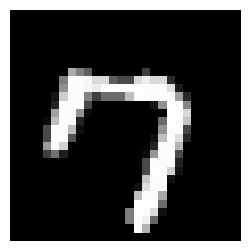

In [293]:
# Verify the dataset has loaded correctly

# Show a single image

dataiter = iter(train_loader)
images, labels = next(dataiter)
images = images.numpy()
img = np.squeeze(images[3])

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(111)

ax.imshow(img, cmap='gray')
ax.axis('off')
plt.show()

### 2. Define the Model Architecture (generator and discriminator)

In [295]:
# Define the generator

def create_generator():
    generator = nn.Sequential(
        nn.Linear(LATENT_DIM, GEN_HIDDEN_DIMS[0]), # 100 -> 32 
        nn.LeakyReLU(GEN_LEAKY_SLOPE),             # Activation function
        nn.Dropout(GEN_DROPOUT),                   # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[0], GEN_HIDDEN_DIMS[1]), # 32 -> 64
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[1], GEN_HIDDEN_DIMS[2]), # 64 -> 128
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[2], GEN_OUTPUT_DIM),     # 128 -> 784
        nn.Tanh()                                          # Scale output to [-1, 1]
    )

    return generator

In [296]:
# Define the discriminator

def create_discriminator():
    discriminator = nn.Sequential(
        nn.Flatten(), # Flatten 28x28 images into 784 features

        nn.Linear(DISC_INPUT_DIM, DISC_HIDDEN_DIMS[0]), # 784 -> 128
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                 # Activation function
        nn.Dropout(DISC_DROPOUT),                       # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[0], DISC_HIDDEN_DIMS[1]), # 128 -> 64
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function 
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[1], DISC_HIDDEN_DIMS[2]), # 64 -> 32 
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting 

        nn.Linear(DISC_HIDDEN_DIMS[2], DISC_OUTPUT_DIM)      # 32 -> 1 (real/fake logit)
    )

    return discriminator

#### Check the layers of the model

This is only for debugging purposes. The true generator and discriminator will be created below.

In [299]:
# Import torchinfo for pretty print of the layers of
# the generator and discriminator
from torchinfo import summary

CURRENT_SEED = 0

torch.manual_seed(RANDOM_SEEDS[CURRENT_SEED])
np.random.seed(RANDOM_SEEDS[CURRENT_SEED])

# instantiate generator 
G_view = create_generator()

# instantiate discriminator
D_view = create_discriminator()

In [300]:
# Display the layers of the generator
# print(G)

# Generator
print('Generator')
summary(G_view, input_size=(BATCH_SIZE, LATENT_DIM))

Generator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 784]                 --
├─Linear: 1-1                            [64, 32]                  3,232
├─LeakyReLU: 1-2                         [64, 32]                  --
├─Dropout: 1-3                           [64, 32]                  --
├─Linear: 1-4                            [64, 64]                  2,112
├─LeakyReLU: 1-5                         [64, 64]                  --
├─Dropout: 1-6                           [64, 64]                  --
├─Linear: 1-7                            [64, 128]                 8,320
├─LeakyReLU: 1-8                         [64, 128]                 --
├─Dropout: 1-9                           [64, 128]                 --
├─Linear: 1-10                           [64, 784]                 101,136
├─Tanh: 1-11                             [64, 784]                 --
Total params: 114,800
Trainable params: 114,800
Non-trainable params: 0

In [301]:
# Display the layers of the discriminator
# print(D)

# Discriminator
print('Discriminator')
summary(D_view, input_size=(BATCH_SIZE, 1, 28, 28))

Discriminator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 1]                   --
├─Flatten: 1-1                           [64, 784]                 --
├─Linear: 1-2                            [64, 128]                 100,480
├─LeakyReLU: 1-3                         [64, 128]                 --
├─Dropout: 1-4                           [64, 128]                 --
├─Linear: 1-5                            [64, 64]                  8,256
├─LeakyReLU: 1-6                         [64, 64]                  --
├─Dropout: 1-7                           [64, 64]                  --
├─Linear: 1-8                            [64, 32]                  2,080
├─LeakyReLU: 1-9                         [64, 32]                  --
├─Dropout: 1-10                          [64, 32]                  --
├─Linear: 1-11                           [64, 1]                   33
Total params: 110,849
Trainable params: 110,849
Non-trainable params: 0
To

### 3. Configure the Loss Functions and Optimizers

In [303]:
# The loss functions that help the discriminator distinguish 
# real from fake images

# distinguish real images
def real_loss(D_out, smooth=False):
    batch_size = D_out.size(0)

    # label smoothing
    if smooth:
        labels = torch.ones(batch_size) * SMOOTH_REAL_LABEL
    else:
        labels = torch.ones(batch_size)

    criterion = nn.BCEWithLogitsLoss()
    
    loss = criterion(D_out.squeeze(-1), labels)

    return loss

# distinguish fake images
def fake_loss(D_out):
    batch_size = D_out.size(0)
    labels = torch.zeros(batch_size)
    
    criterion = nn.BCEWithLogitsLoss()

    loss = criterion(D_out.squeeze(-1), labels)
    
    return loss

In [304]:
import torch.optim as optim

def create_optimizers(G, D):
    # Create optimizers for the generator and discriminator
    g_optimizer = optim.Adam(G.parameters(), lr=OPTIMIZERS_LEARNING_RATE)
    d_optimizer = optim.Adam(D.parameters(), lr=OPTIMIZERS_LEARNING_RATE)

    return g_optimizer, d_optimizer

### 4. Train the Model

In [306]:
# Save the results for one random seed
def save_results(seed, G, D, losses, samples):

    torch.save({
        "seed": seed,
        "generator": G.state_dict(),
        "discriminator": D.state_dict(),
        "losses": losses,
        "samples": samples,
        "config": {
            "epochs": NUM_EPOCHS,
            "batch_size": BATCH_SIZE,
            "latent_dim": Z_SIZE,
            "truncation": TRUNCATION,
            "learning_rate": OPTIMIZERS_LEARNING_RATE,
            "label_smoothing": LABEL_SMOOTHING,
            "gen_hidden_dims": GEN_HIDDEN_DIMS,
            "disc_hidden_dims": DISC_HIDDEN_DIMS
        }
    }, EXPERIMENT_DIR / f"seed_{seed}.pt")

In [307]:
def train_discriminator(real_images, G, D, d_optimizer):
    batch_size = real_images.size(0)

    d_optimizer.zero_grad()

    # Train with real images
    D_real = D(real_images)
    d_real_loss = real_loss(D_real, smooth=LABEL_SMOOTHING)

    # Train with fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    D_fake = D(fake_images.detach())
    d_fake_loss = fake_loss(D_fake)

    # Update discriminator
    d_loss = d_real_loss + d_fake_loss
    d_loss.backward()
    d_optimizer.step()

    return d_loss


def train_generator(real_images, G, D, g_optimizer):
    batch_size = real_images.size(0)

    g_optimizer.zero_grad()

    # Generate fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    # Train with flipped labels
    D_fake = D(fake_images)
    g_loss = real_loss(D_fake)

    # Update generator
    g_loss.backward()
    g_optimizer.step()

    return g_loss

In [308]:
RESULTS_DIR.mkdir(exist_ok=True)


# Train the GAN for one random seed
def train_one_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Instantiate generator and discriminator
    G = create_generator()
    D = create_discriminator()

    # Create fresh optimizers
    g_optimizer, d_optimizer = create_optimizers(G, D)

    # Store generated images and training losses
    samples = []
    losses = []

    # Fixed random noise
    fixed_z = np.random.uniform(-1, 1, size=(SAMPLE_SIZE, Z_SIZE))
    fixed_z = torch.from_numpy(fixed_z).float()

    G.train()
    D.train()

    for epoch in range(NUM_EPOCHS):
        for batch_i, (real_images, _) in enumerate(train_loader):
            batch_size = real_images.size(0)

            # Rescale images from [0, 1] to [-1, 1]
            real_images = real_images * 2 - 1

            # Train discriminator
            d_loss = train_discriminator(
                real_images, G, D, d_optimizer
            )

            # Train generator
            g_loss = train_generator(
                real_images, G, D, g_optimizer
            )

            if batch_i % PRINT_EVERY == 0:
                print(
                    f"Seed {seed} | Epoch [{epoch+1}/{NUM_EPOCHS}] "
                    f"| d_loss: {d_loss.item():.4f} "
                    f"| g_loss: {g_loss.item():.4f}"
                )

        # Store losses after each epoch
        losses.append((d_loss.item(), g_loss.item()))

        # Generate and save sample images
        G.eval()

        with torch.no_grad():
            samples_z = G(fixed_z * TRUNCATION)
            samples.append(samples_z.cpu())

        G.train()

    return G, D, losses, samples

In [309]:
# Train and save the GAN for each random seed
if QUICK:
    print("Loading saved results")
    
    for seed in RANDOM_SEEDS:
        checkpoint_path = EXPERIMENT_DIR / f"seed_{seed}.pt"

        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpoint_path}"
            )

    print("All 3 checkpoints found. Ready for evaluation.")
else:
    for seed in RANDOM_SEEDS:
        G, D, losses, samples = train_one_seed(seed)
        save_results(seed, G, D, losses, samples)

Seed 42 | Epoch [1/100] | d_loss: 1.3959 | g_loss: 0.6788
Seed 42 | Epoch [1/100] | d_loss: 1.0292 | g_loss: 2.3218
Seed 42 | Epoch [1/100] | d_loss: 1.2148 | g_loss: 1.0816
Seed 42 | Epoch [2/100] | d_loss: 1.6865 | g_loss: 0.8146
Seed 42 | Epoch [2/100] | d_loss: 1.2676 | g_loss: 1.3854
Seed 42 | Epoch [2/100] | d_loss: 1.7511 | g_loss: 0.4377
Seed 42 | Epoch [3/100] | d_loss: 1.2349 | g_loss: 0.9558
Seed 42 | Epoch [3/100] | d_loss: 1.2355 | g_loss: 0.6633
Seed 42 | Epoch [3/100] | d_loss: 0.9476 | g_loss: 1.2041
Seed 42 | Epoch [4/100] | d_loss: 1.0388 | g_loss: 1.4473
Seed 42 | Epoch [4/100] | d_loss: 1.0589 | g_loss: 0.9843
Seed 42 | Epoch [4/100] | d_loss: 1.1252 | g_loss: 1.4936
Seed 42 | Epoch [5/100] | d_loss: 0.9161 | g_loss: 1.6340
Seed 42 | Epoch [5/100] | d_loss: 1.0201 | g_loss: 1.0993
Seed 42 | Epoch [5/100] | d_loss: 0.8497 | g_loss: 1.9650
Seed 42 | Epoch [6/100] | d_loss: 0.9974 | g_loss: 0.9491
Seed 42 | Epoch [6/100] | d_loss: 1.0031 | g_loss: 1.5724
Seed 42 | Epoc

### 5. Evaluate the Model

##### a) Load results function

In [312]:
# Load trained models and results
def load_results(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    # Load training losses and generated samples
    losses = checkpoint["losses"]
    samples = checkpoint["samples"]

    # Recreate models
    G = create_generator()
    D = create_discriminator()

    # Load trained weights
    G.load_state_dict(checkpoint["generator"])
    D.load_state_dict(checkpoint["discriminator"])

    G.eval()
    D.eval()

    return G, D, losses, samples

##### b) Evaluate discriminator function

In [314]:
# Evaluate discriminator accuracy

def evaluate_discriminator(G, D, test_loader):
    G.eval()
    D.eval()

    real_correct = 0
    fake_correct = 0
    total = 0

    with torch.no_grad():
        for real_images, _ in test_loader:
            batch_size = real_images.size(0)

            # Real images
            real_images = real_images * 2 - 1
            D_real = D(real_images)
            real_correct += (D_real.reshape(-1) > 0).sum().item()

            # Fake images
            z = torch.rand(batch_size, Z_SIZE) * 2 - 1
            fake_images = G(z)

            D_fake = D(fake_images)
            fake_correct += (D_fake.reshape(-1) < 0).sum().item()

            total += batch_size

    # Calculate accuracy
    real_accuracy = real_correct / total * 100
    fake_accuracy = fake_correct / total * 100
    total_accuracy = (real_correct + fake_correct) / (2 * total) * 100

    print(f"Real image accuracy: {real_accuracy:.2f}%")
    print(f"Fake image accuracy: {fake_accuracy:.2f}%")
    print(f"Overall discriminator accuracy: {total_accuracy:.2f}%")

    return real_accuracy, fake_accuracy, total_accuracy

##### c) Evaluate generator function

In [316]:
# Evaluate generator fooling rate

def evaluate_generator(G, D, num_samples=10000, batch_size=64):
    G.eval()
    D.eval()

    device = next(G.parameters()).device
    rng = torch.Generator().manual_seed(999)

    fooled = 0

    with torch.no_grad():
        for i in range(0, num_samples, batch_size):
            n = min(batch_size, num_samples - i)

            # Generate fake images
            z = torch.rand(n, Z_SIZE, generator=rng).to(device) * 2 - 1
            fake_images = G(z)

            # Discriminator predictions
            D_fake = D(fake_images)

            # Count fake images classified as real
            fooled += (D_fake.reshape(-1) > 0).sum().item()

    generator_fooling_rate = fooled / num_samples * 100

    print(f"Generator fooling rate: {generator_fooling_rate:.2f}%")

    return generator_fooling_rate

##### d) Evaluate probabilities

In [318]:
# Evaluate discriminator probabilities

def evaluate_probabilities(G, D, test_loader):
    G.eval()
    D.eval()

    device = next(G.parameters()).device
    rng = torch.Generator().manual_seed(999)

    with torch.no_grad():
        real_images, _ = next(iter(test_loader))
        real_images = real_images.to(device) * 2 - 1

        # Generate fake images
        z = torch.rand(real_images.size(0), Z_SIZE, generator=rng).to(device) * 2 - 1
        fake_images = G(z)

        # Discriminator predictions
        real_logits = D(real_images)
        fake_logits = D(fake_images)

        real_probability = torch.sigmoid(real_logits).mean().item()
        fake_probability = torch.sigmoid(fake_logits).mean().item()

    print(f"Mean real probability: {real_probability:.4f}")
    print(f"Mean fake probability: {fake_probability:.4f}")

    return real_probability, fake_probability

##### e) Generator parameters

In [320]:
# Verify that the generator weights are updated

def check_generator_update(train_loader):

    # Initialize temporary models
    G = create_generator()
    D = create_discriminator()

    # Initialize optimizers
    g_optimizer, d_optimizer = create_optimizers(G, D)

    # Save generator weights before training
    before = [p.detach().clone() for p in G.parameters()]

    # Train generator for one step
    real_images, _ = next(iter(train_loader))
    g_loss = train_generator(real_images, G, D, g_optimizer)

    # Compare weights
    weight_change = sum(
        (after.detach() - previous).abs().sum().item()
        for after, previous in zip(G.parameters(), before)
    )

    print(f"Generator weight change: {weight_change:.6f}")

    return weight_change

##### Use the implemented functions to evaluate the model

In [322]:
evaluation_results = {}

for seed in RANDOM_SEEDS:
    
    # Load trained models
    G, D, losses, samples = load_results(seed)

    print(f"\n{'=' * 40}")
    print(f"Evaluating Seed {seed}")
    print(f"{'=' * 40}")

    # Evaluate discriminator accuracy
    real_acc, fake_acc, total_acc = evaluate_discriminator(
        G, D, test_loader
    )

    # Evaluate generator fooling rate
    fooling_rate = evaluate_generator(G, D)

    # Evaluate discriminator probabilities
    real_prob, fake_prob = evaluate_probabilities(
        G, D, test_loader
    )

    # Store evaluation results
    evaluation_results[seed] = {
        "real_accuracy": real_acc,
        "fake_accuracy": fake_acc,
        "total_accuracy": total_acc,
        "fooling_rate": fooling_rate,
        "real_probability": real_prob,
        "fake_probability": fake_prob
    }

    # Release memory
    del G, D, losses, samples


Evaluating Seed 42
Real image accuracy: 46.06%
Fake image accuracy: 99.99%
Overall discriminator accuracy: 73.02%
Generator fooling rate: 0.00%
Mean real probability: 0.5110
Mean fake probability: 0.2943

Evaluating Seed 123
Real image accuracy: 45.85%
Fake image accuracy: 99.96%
Overall discriminator accuracy: 72.91%
Generator fooling rate: 0.01%
Mean real probability: 0.5602
Mean fake probability: 0.2993

Evaluating Seed 456
Real image accuracy: 50.70%
Fake image accuracy: 98.61%
Overall discriminator accuracy: 74.66%
Generator fooling rate: 1.29%
Mean real probability: 0.5582
Mean fake probability: 0.3629


##### Evalute the mean and std

In [324]:
df = pd.DataFrame.from_dict(
    evaluation_results,
    orient="index"
)

df.index.name = "Seed"

display(df.round(3))

# Calculate mean and standard deviation
statistics = df.agg(["mean", "std"])
display(statistics.round(3))

,real_accuracy,fake_accuracy,total_accuracy,fooling_rate,real_probability,fake_probability
Seed,,,,,,
42,46.06,99.99,73.025,0.00,0.511,0.294
123,45.85,99.96,72.905,0.01,0.560,0.299
456,50.70,98.61,74.655,1.29,0.558,0.363


,real_accuracy,fake_accuracy,total_accuracy,fooling_rate,real_probability,fake_probability
mean,47.537,99.520,73.528,0.433,0.543,0.319
std,2.742,0.788,0.978,0.742,0.028,0.038


### 5. Evaluate 

In [372]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU()
        )

        self.output = nn.Linear(128, 10)

    def forward(self, x):
        features = self.features(x)
        logits = self.output(features)
        return logits, features


torch.manual_seed(2026)
classifier = MNISTClassifier()
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)

for epoch in range(3):
    classifier.train()

    for images, labels in train_loader:
        optimizer.zero_grad()

        logits, _ = classifier(images)
        loss = F.cross_entropy(logits, labels)

        loss.backward()
        optimizer.step()

# Verify accuracy on real MNIST test images
classifier.eval()
correct = total = 0

with torch.no_grad():
    for images, labels in test_loader:
        logits, _ = classifier(images)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

print(f"Classifier test accuracy: {100 * correct / total:.2f}%")

Classifier test accuracy: 98.75%


In [373]:

def evaluate_image_quality_diversity(
    G, classifier, truncation, num_samples=5000
):
    G.eval()
    classifier.eval()

    rng = torch.Generator().manual_seed(999)

    confidences = []
    predictions = []
    embeddings = []

    with torch.no_grad():
        for i in range(0, num_samples, 256):
            n = min(256, num_samples - i)

            # Same underlying latent samples for comparison
            z = (
                torch.rand(n, Z_SIZE, generator=rng) * 2 - 1
            ) * truncation

            # Generate MNIST images
            images = G(z).reshape(-1, 1, 28, 28)

            # Convert from [-1, 1] to [0, 1]
            images = ((images + 1) / 2).clamp(0, 1)

            # Classify generated images
            logits, features = classifier(images)

            probabilities = F.softmax(logits, dim=1)
            confidence, predicted = probabilities.max(dim=1)

            confidences.append(confidence)
            predictions.append(predicted)
            embeddings.append(F.normalize(features, dim=1))

    confidences = torch.cat(confidences)
    predictions = torch.cat(predictions)
    embeddings = torch.cat(embeddings)

    # 1. Quality: mean classification confidence
    quality = confidences.mean().item()

    # 2. Diversity: normalised class entropy
    counts = torch.bincount(predictions, minlength=10).float()
    probabilities = counts / counts.sum()

    entropy = -(
        probabilities * torch.log(probabilities + 1e-12)
    ).sum() / np.log(10)

    # 3. Within-class diversity: feature dispersion
    spreads = []

    for digit in range(10):
        digit_features = embeddings[predictions == digit]

        if len(digit_features) > 1:
            mean_feature = digit_features.mean(dim=0)
            spread = 1 - mean_feature.square().sum().item()
            spreads.append(spread)

    within_class_diversity = np.mean(spreads) if spreads else np.nan

    return {
        "quality": quality,
        "class_entropy": entropy.item(),
        "within_class_diversity": within_class_diversity
    }


In [374]:

results = []

for truncation, folder in TRUNCATION_FOLDERS.items():
    for seed in RANDOM_SEEDS:

        checkpoint = torch.load(
            RESULTS_DIR / folder / f"seed_{seed}.pt",
            map_location="cpu",
            weights_only=True
        )

        G = create_generator()
        G.load_state_dict(checkpoint["generator"])

        metrics = evaluate_image_quality_diversity(
            G, classifier, truncation
        )

        results.append({
            "truncation": truncation,
            "seed": seed,
            **metrics
        })

df = pd.DataFrame(results)

summary = df.groupby("truncation")[
    ["quality", "class_entropy", "within_class_diversity"]
].agg(["mean", "std"])

display(summary.round(3))

quality        class_entropy        within_class_diversity       
              mean    std          mean    std                   mean    std
truncation                                                                  
0.25         0.885  0.100         0.650  0.563                  0.124  0.108
0.50         0.731  0.132         0.330  0.539                  0.062  0.103
1.00         0.800  0.026         0.935  0.006                  0.199  0.007
1.50         0.834  0.004         0.961  0.006                  0.192  0.007
2.00         0.826  0.012         0.972  0.013                  0.188  0.010

### 6. View results

##### a) Plot losses

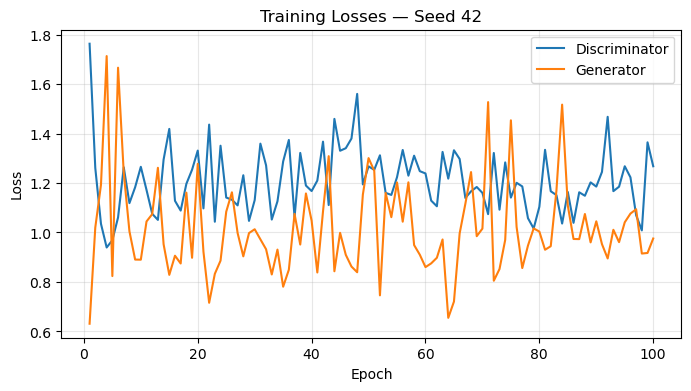

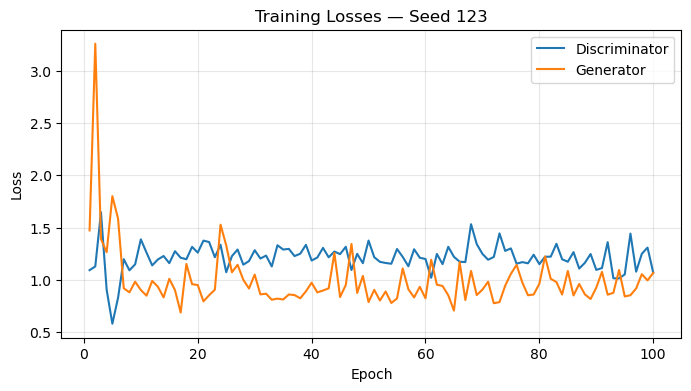

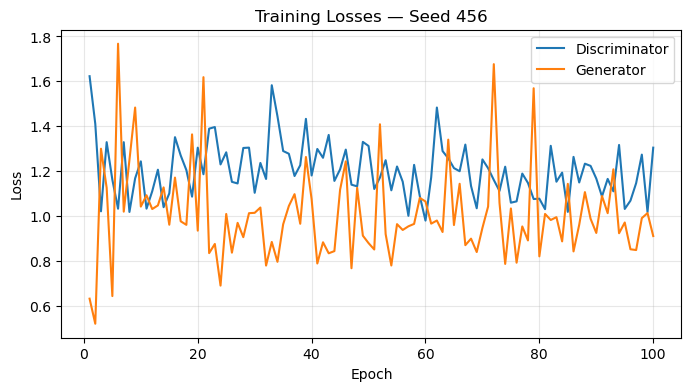

In [327]:
# Plot training losses for a specific seed

def plot_training_losses(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    losses = np.array(checkpoint["losses"])
    epochs = np.arange(1, len(losses) + 1)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(epochs, losses[:, 0], label="Discriminator")
    ax.plot(epochs, losses[:, 1], label="Generator")

    ax.set_title(f"Training Losses — Seed {seed}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.show()

for seed in RANDOM_SEEDS:
    plot_training_losses(seed)

##### b) Visualize Training progress

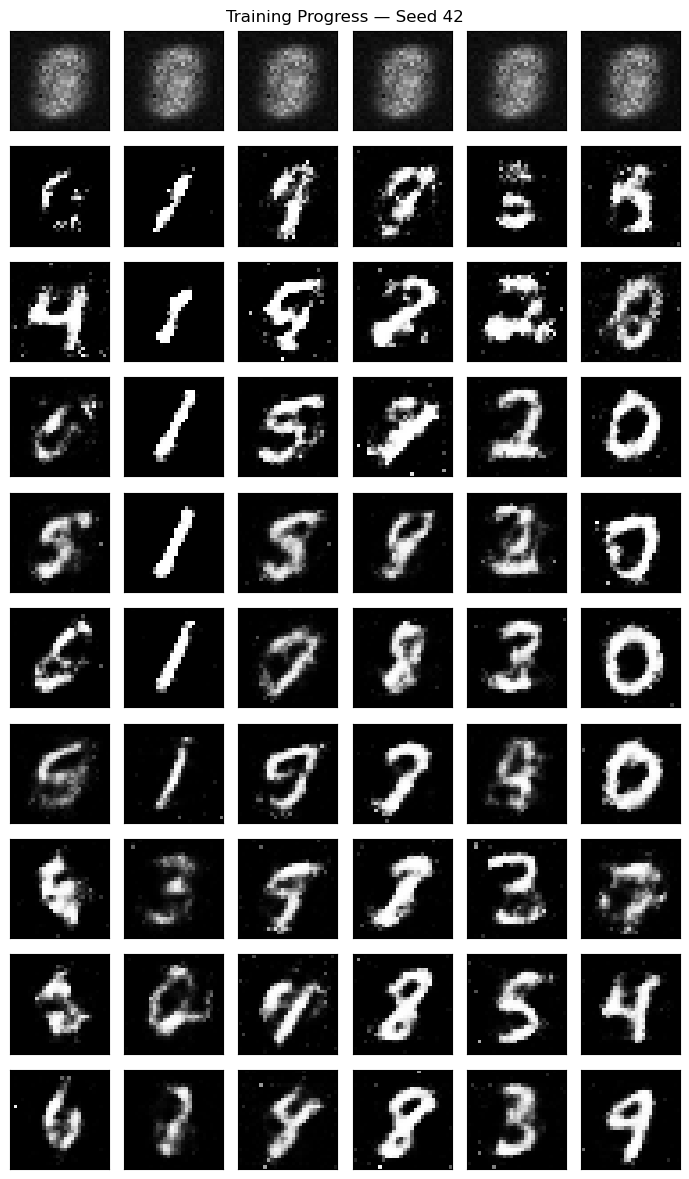

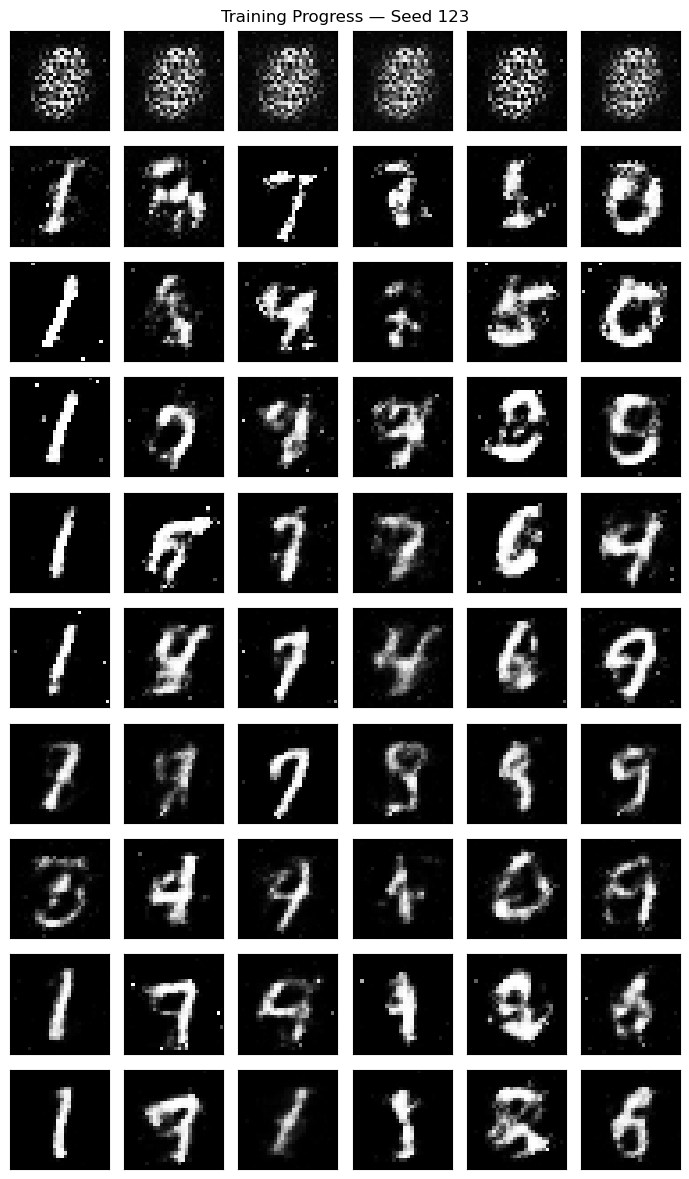

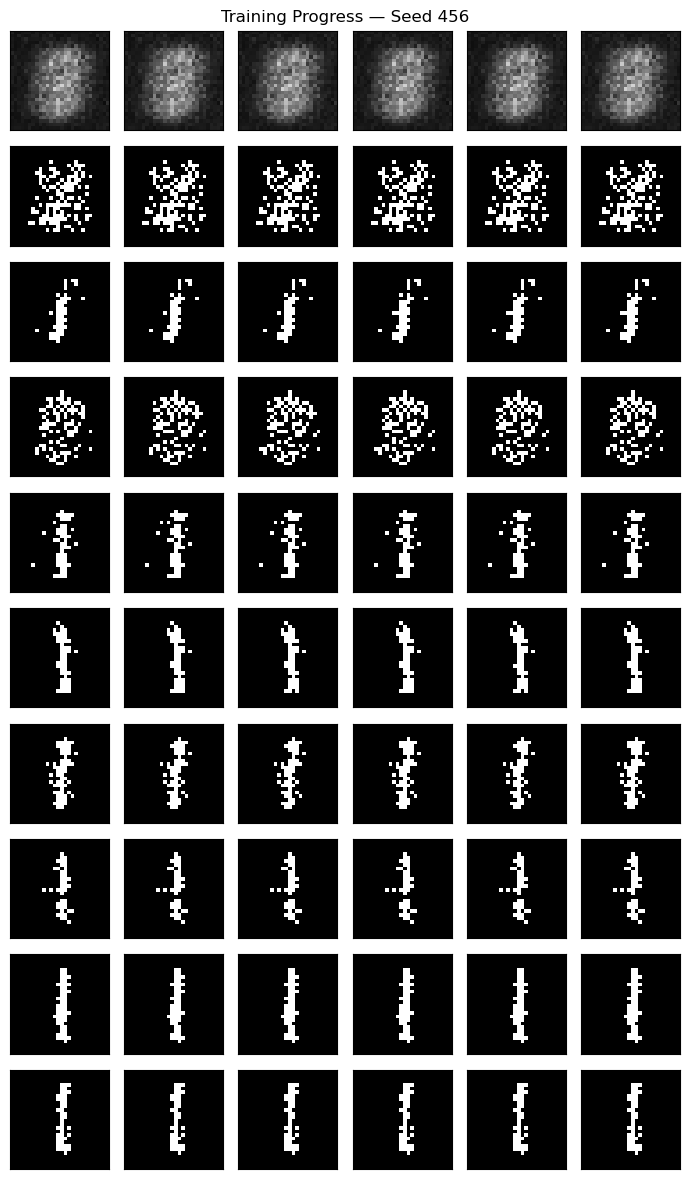

In [380]:
# Visualize generated images across training epochs

def view_training_progress(seed):
    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    rows = min(10, len(samples))  # Display up to 10 training stages
    cols = min(6, len(samples[0]))

    # Select evenly spaced stages, including the final one
    stages = np.linspace(0, len(samples) - 1, rows, dtype=int)
    image_indices = np.linspace(0, len(samples[0]) - 1, cols, dtype=int)

    fig, axes = plt.subplots(
        figsize=(7, 12),
        nrows=rows,
        ncols=cols,
        sharex=True,
        sharey=True,
        squeeze=False
    )

    for stage, ax_row in zip(stages, axes):
        for img_idx, ax in zip(image_indices, ax_row):
            img = samples[stage][img_idx].detach().cpu().numpy()
            ax.imshow(img.reshape((28, 28)), cmap="Greys_r", vmin=-1, vmax=1)
            ax.xaxis.set_visible(False)
            ax.yaxis.set_visible(False)

    fig.suptitle(f"Training Progress — Seed {seed}")
    plt.tight_layout()
    plt.show()

for seed in RANDOM_SEEDS: 
    view_training_progress(seed)

##### c) Visualize final results

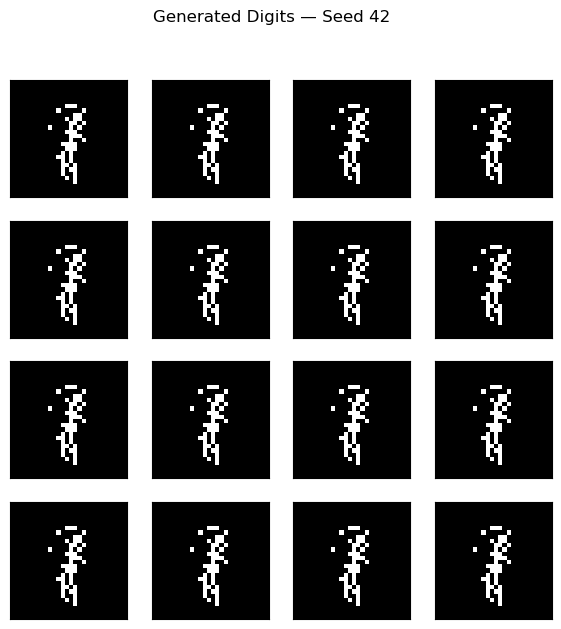

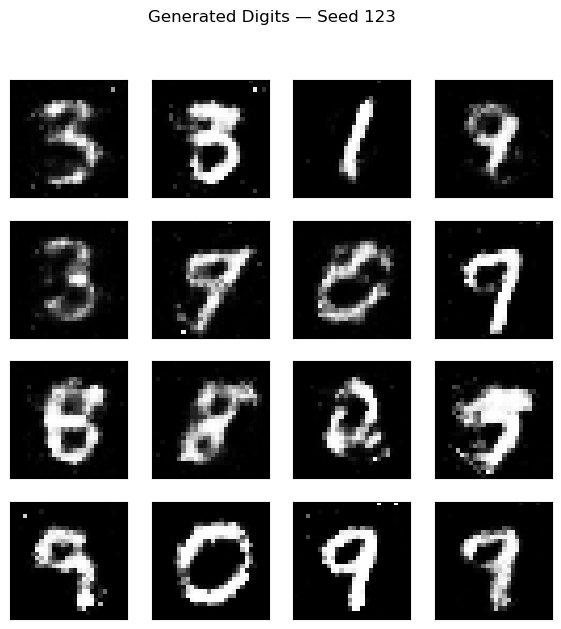

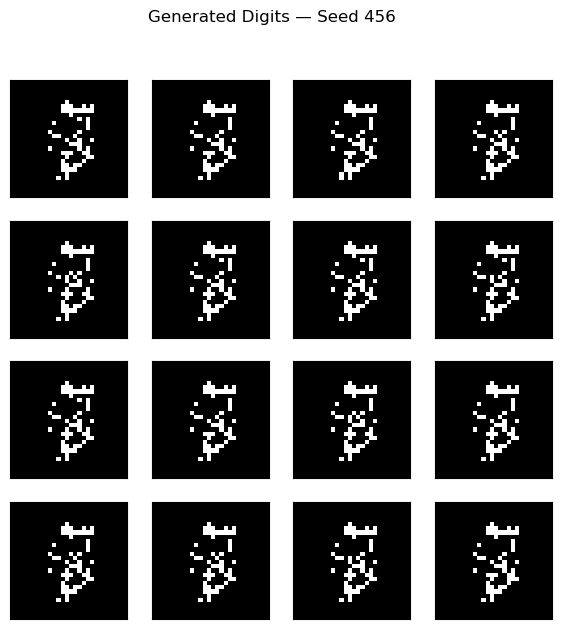

In [384]:
# View generated images for a specific seed

def view_samples(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    fig, axes = plt.subplots(
        figsize=(7, 7),
        nrows=4, ncols=4,
        sharey=True, sharex=True
    )

    for ax, img in zip(axes.flatten(), samples[-1]):
        img = img.detach().cpu().numpy()
        ax.xaxis.set_visible(False)
        ax.yaxis.set_visible(False)
        ax.imshow(img.reshape((28, 28)), cmap="Greys_r")

    fig.suptitle(f"Generated Digits — Seed {seed}")
    plt.show()


for seed in RANDOM_SEEDS:
    view_samples(seed)

### 7. Discussion and Conclusions